   #                           **Retail & Grocery Sales Analytics**

# **Objective 1: Understand the Business and Its Sales Performance**

In [1]:
#Import Libraries and Load Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Upload file in Colab
from google.colab import files
uploaded = files.upload()

# Read dataset
df = pd.read_excel('BlinkIT Grocery Data.xlsx')

# First 5 rows
df.head()



Saving BlinkIT Grocery Data.xlsx to BlinkIT Grocery Data.xlsx


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [2]:
print("Rows and Columns:")
print(df.shape)
print(df.columns)
df.info()
df.describe()

Rows and Columns:
(8523, 12)
Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-nul

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2016.450546,0.066132,12.857645,140.992783,3.965857
std,3.189396,0.051598,4.643456,62.275067,0.605651
min,2011.000000,0.000000,4.555000,31.290000,1.000000
25%,2014.000000,0.026989,8.773750,93.826500,4.000000
50%,2016.000000,0.053931,12.600000,143.012800,4.000000
75%,2018.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


In [3]:
df = df.rename(columns={'Item Fat Content':'fat_content','Item Identifier':'item_id','Item Type':'item_type',
                        'Outlet Establishment Year':'est_year','Outlet Identifier':'outlet_id',
                        'Outlet Location Type':'location','Outlet Size':'size','Outlet Type':'outlet_type',
                        'Item Visibility':'visibility','Item Weight':'weight','Sales':'sales','Rating':'rating'})
df['group'] = df['item_id'].str[:2].map({'FD':'Food','DR':'Drinks','NC':'Non-Consumable'})
print(df.columns.tolist())

['fat_content', 'item_id', 'item_type', 'est_year', 'outlet_id', 'location', 'size', 'outlet_type', 'visibility', 'weight', 'sales', 'rating', 'group']


In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 14, 'axes.titleweight': 'bold',
                     'axes.labelsize': 12, 'xtick.labelsize': 11, 'ytick.labelsize': 11})

def hbar(series, title, xlabel, color='teal', fmt='{:,.0f}', figsize=(10, 6)):
    # Sorted horizontal bar chart with value labels on every bar
    series = series.sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(series.index.astype(str), series.values, color=color)
    for b, v in zip(bars, series.values):
        ax.text(b.get_width(), b.get_y() + b.get_height()/2, '  ' + fmt.format(v), va='center', fontsize=10)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('')
    ax.set_xlim(0, series.max() * 1.15); ax.grid(axis='y', visible=False)
    plt.tight_layout(); plt.show()

#**Task 1.1: Understand what types of products BlinkIT is selling.**



Rows (item-outlet records): 8523
Unique items: 1559
Item types: 16

                unique_items  records  share_pct
group                                           
Drinks                   145      799        9.4
Food                    1119     6125       71.9
Non-Consumable           295     1599       18.8


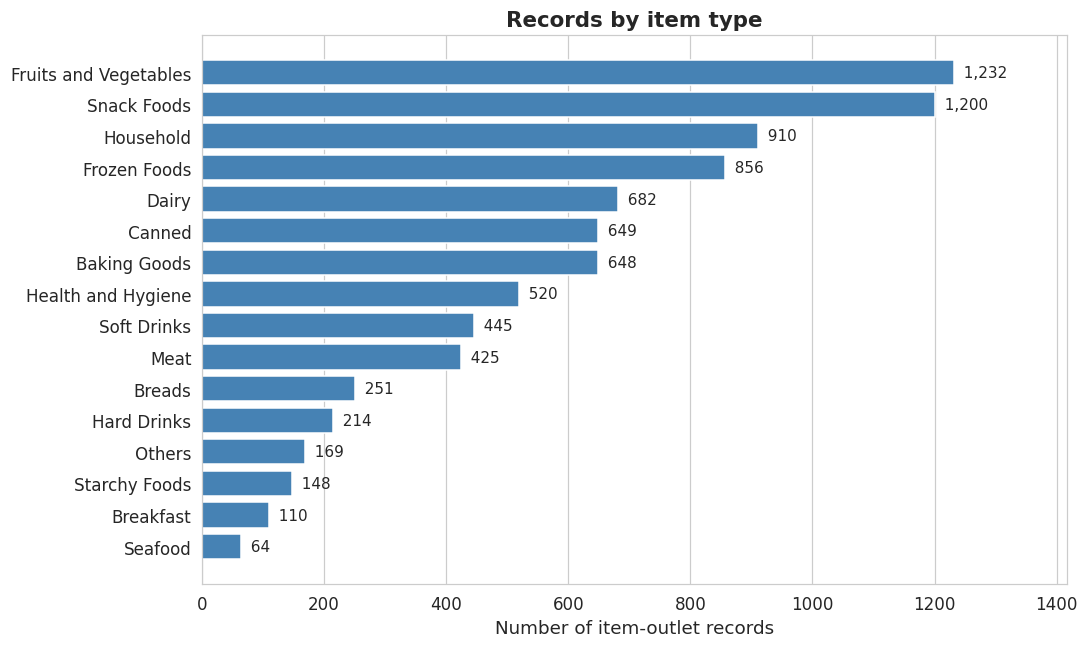

In [5]:
print('Rows (item-outlet records):', len(df))
print('Unique items:', df['item_id'].nunique())
print('Item types:', df['item_type'].nunique())
print()
print(df.groupby('group').agg(unique_items=('item_id','nunique'), records=('sales','size')).assign(share_pct=lambda x: (x['records']/x['records'].sum()*100).round(1)))
hbar(df['item_type'].value_counts(), 'Records by item type', 'Number of item-outlet records', 'steelblue')



**Observation:** BlinkIT lists **1,559 unique items** across **16 item types** (8,523 item-outlet records). Food dominates (72% of records, 1,119 items), followed by non-consumables (19%) and drinks (9%). Fruits & Vegetables, Snack Foods and Household are the widest ranges; Seafood (64 records) and Breakfast (110) are the narrowest.


# **Task 1.2: Types and locations of BlinkIT outlets**

                 outlet_type location  est_year  records  total_sales
outlet_id                                                            
OUT035     Supermarket Type1   Tier 2      2017      930     133104.0
OUT046     Supermarket Type1   Tier 1      2016      930     132113.0
OUT013     Supermarket Type1   Tier 3      2014      932     131809.0
OUT018     Supermarket Type2   Tier 3      2022      928     131478.0
OUT045     Supermarket Type1   Tier 2      2015      929     130943.0
OUT027     Supermarket Type3   Tier 3      2018      935     130715.0
OUT049     Supermarket Type1   Tier 1      2012      930     130477.0
OUT017     Supermarket Type1   Tier 2      2020      926     129104.0
OUT010         Grocery Store   Tier 3      2011      555      78132.0
OUT019         Grocery Store   Tier 1      2018      528      73808.0

Outlets by type x location:
location           Tier 1  Tier 2  Tier 3  All
outlet_type                                   
Grocery Store           1       0    

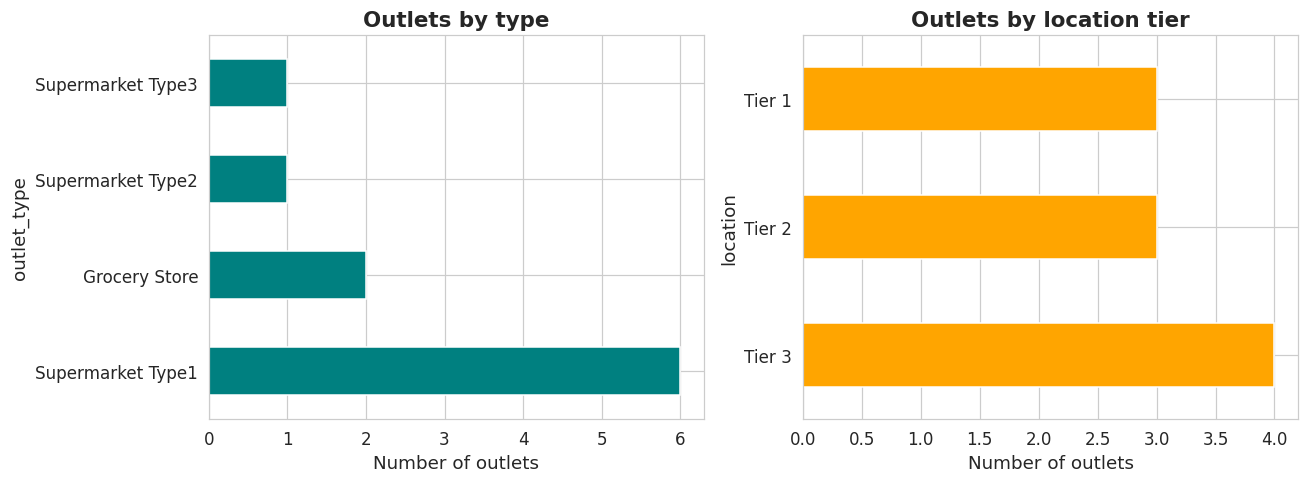

In [6]:
outlets = df.groupby('outlet_id').agg(outlet_type=('outlet_type','first'), location=('location','first'),
                                     est_year=('est_year','first'), records=('sales','size'),
                                     total_sales=('sales','sum')).round(0)
print(outlets.sort_values('total_sales', ascending=False))
print()
print('Outlets by type x location:')
print(pd.crosstab(outlets['outlet_type'], outlets['location'], margins=True))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
outlets['outlet_type'].value_counts().plot.barh(ax=ax[0], color='teal'); ax[0].set_title('Outlets by type'); ax[0].set_xlabel('Number of outlets')
outlets['location'].value_counts().plot.barh(ax=ax[1], color='orange'); ax[1].set_title('Outlets by location tier'); ax[1].set_xlabel('Number of outlets')
plt.tight_layout(); plt.show()


**Observation:** BlinkIT has **10 outlets**: 2 grocery stores, 6 Supermarket Type1, 1 Type2 and 1 Type3, spread over Tier 1 (3 outlets), Tier 2 (3) and Tier 3 (4). Outlets opened between 2011 and 2022. The two grocery stores stock only 528-555 records each, versus about 930 in every supermarket.

# **Task 1.3: How much is BlinkIT selling overall?**

Total sales          : 1,201,681
Average per record   : 141.0
Median per record    : 143.0
Min / Max per record : 31.3 / 266.9


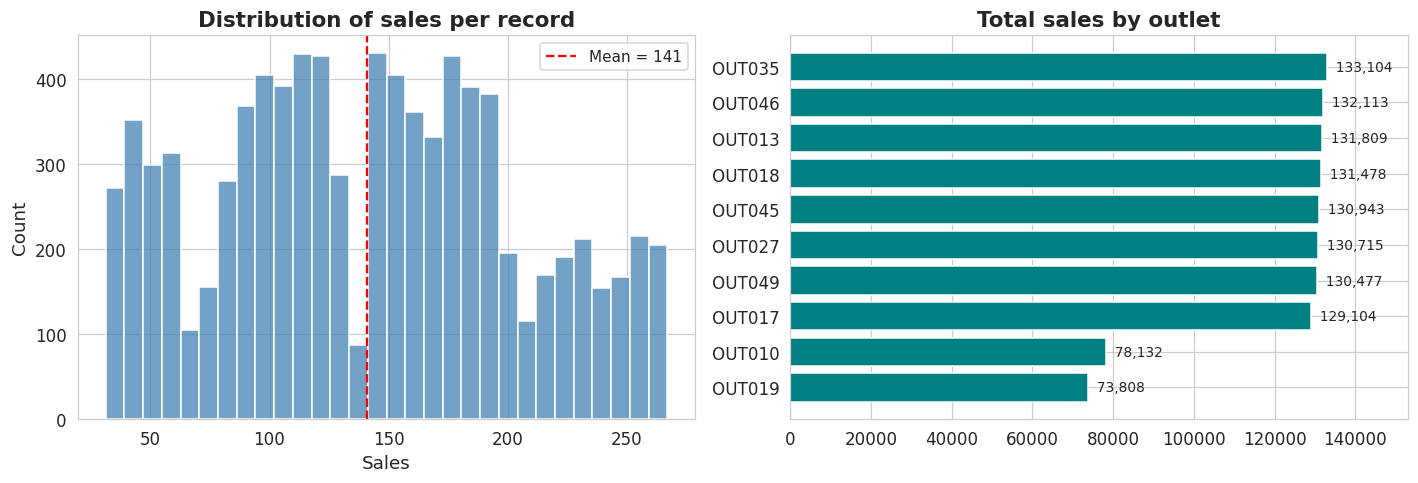

In [7]:
print(f"Total sales          : {df['sales'].sum():,.0f}")
print(f"Average per record   : {df['sales'].mean():,.1f}")
print(f"Median per record    : {df['sales'].median():,.1f}")
print(f"Min / Max per record : {df['sales'].min():,.1f} / {df['sales'].max():,.1f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df['sales'], bins=30, color='steelblue', ax=ax[0])
ax[0].axvline(df['sales'].mean(), color='red', ls='--', label=f"Mean = {df['sales'].mean():.0f}")
ax[0].set_title('Distribution of sales per record'); ax[0].set_xlabel('Sales'); ax[0].legend()
hbar_data = df.groupby('outlet_id')['sales'].sum().sort_values()
ax[1].barh(hbar_data.index, hbar_data.values, color='teal')
for i, v in enumerate(hbar_data.values): ax[1].text(v, i, f'  {v:,.0f}', va='center', fontsize=9)
ax[1].set_title('Total sales by outlet'); ax[1].set_xlim(0, hbar_data.max()*1.15)
plt.tight_layout(); plt.show()

**Observation:** Total sales are **1,201,681**, averaging **141 per record** (median 143, range 31-267). The distribution is roughly symmetric with no long tail. Eight outlets each contribute 129K-133K (about 11% each); the two grocery stores contribute about 74-78K each (6-6.5%).

# **Task 1.4: Overall customer rating and product performance**

Average rating: 3.97 | Median: 4.0
Share of records rated exactly 4.0: 39.2%
Share rated 4.0 or higher         : 76.4%
Share rated below 3.0             : 5.0%


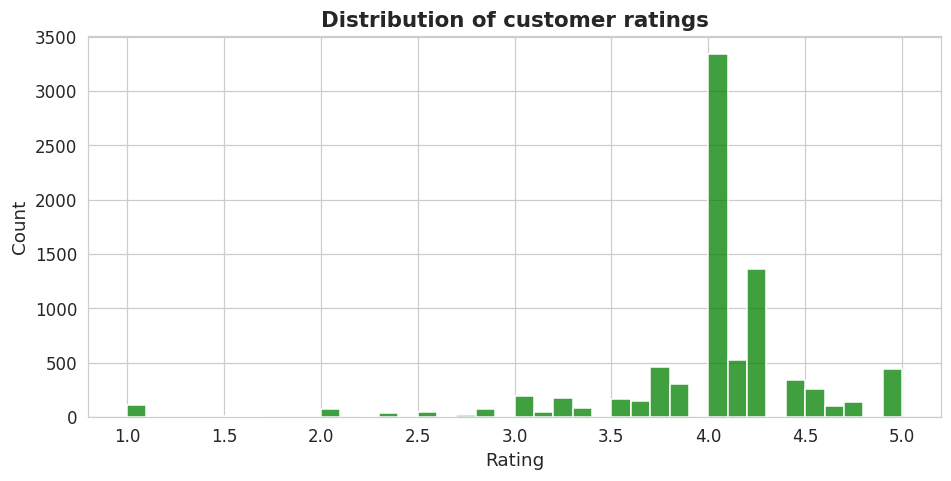

                       avg_rating  avg_sales  total_sales
item_type                                                
Fruits and Vegetables        3.96     144.58    178124.08
Snack Foods                  3.95     146.19    175433.92
Household                    4.00     149.42    135976.53
Frozen Foods                 3.97     138.50    118558.88
Dairy                        3.97     148.50    101276.46
Canned                       3.99     139.76     90706.73
Baking Goods                 3.98     126.38     81894.74
Health and Hygiene           3.99     130.82     68025.84
Meat                         4.02     139.88     59449.86
Soft Drinks                  3.92     131.49     58514.17
Breads                       3.88     140.95     35379.12
Hard Drinks                  3.91     137.08     29334.68
Others                       3.95     132.85     22451.89
Starchy Foods                3.92     147.84     21880.03
Breakfast                    3.93     141.79     15596.70
Seafood       

In [8]:
print(f"Average rating: {df['rating'].mean():.2f} | Median: {df['rating'].median():.1f}")
print(f"Share of records rated exactly 4.0: {(df['rating']==4.0).mean()*100:.1f}%")
print(f"Share rated 4.0 or higher         : {(df['rating']>=4.0).mean()*100:.1f}%")
print(f"Share rated below 3.0             : {(df['rating']<3.0).mean()*100:.1f}%")

plt.figure(figsize=(10, 4.5))
sns.histplot(df['rating'], bins=40, color='green')
plt.title('Distribution of customer ratings'); plt.xlabel('Rating'); plt.show()

rt = df.groupby('item_type').agg(avg_rating=('rating','mean'), avg_sales=('sales','mean'), total_sales=('sales','sum')).round(2)
print(rt.sort_values('total_sales', ascending=False))

**Observation:** The average rating is **3.97**; 76% of records are rated 4.0 or higher and only 5% fall below 3.0, so customers are broadly satisfied. **Caution:** 39% of all records are rated exactly 4.0, a far bigger spike than any other value, which suggests a default or imputed rating. Average rating barely differs across item types (3.88-4.02), with Meat highest and Breads lowest.

# **Objective 2: Make Sure the Available Information Is Reliable**

## **Task 2.1: Missing information**

In [19]:
print('Null values per column:'); print(df.isnull().sum()[lambda s: s>0])
print()
print('Hidden missing values (zero visibility):', (df['visibility']==0).sum(), f"({(df['visibility']==0).mean()*100:.1f}%)")
print()
print('Missing Item Weight by outlet:')
print(df[df['weight'].isna()]['outlet_id'].value_counts())
print()
# Is an item's weight constant across outlets? (decides whether we can fill from other outlets)
print('Max distinct weights for a single item:', df.groupby('item_id')['weight'].nunique().max())

Null values per column:
Series([], dtype: int64)

Hidden missing values (zero visibility): 0 (0.0%)

Missing Item Weight by outlet:
Series([], Name: count, dtype: int64)

Max distinct weights for a single item: 1


**Cleaning decisions**
- `weight`: every missing value sits in two outlets (OUT019, OUT027), but an item has one fixed weight, so we copy it from the same item sold elsewhere; any leftovers use the item-type median.
- `visibility`: a visibility of exactly 0 is impossible for an item on sale, so zeros are treated as missing and replaced with the item's average non-zero visibility.

In [20]:
# Weight: fill from the same item in other outlets, then item-type median
item_weight = df.groupby('item_id')['weight'].transform('max')
df['weight'] = df['weight'].fillna(item_weight)
df['weight'] = df['weight'].fillna(df.groupby('item_type')['weight'].transform('median'))

# Visibility: zeros -> NaN -> item mean -> item-type mean
df['visibility'] = df['visibility'].replace(0, np.nan)
df['visibility'] = df['visibility'].fillna(df.groupby('item_id')['visibility'].transform('mean'))
df['visibility'] = df['visibility'].fillna(df.groupby('item_type')['visibility'].transform('mean'))
print('Remaining nulls:', df[['weight','visibility']].isnull().sum().to_dict())

Remaining nulls: {'weight': 0, 'visibility': 0}


**Observation:** Only `weight` has true nulls (**1,463 rows, 17%**), all in outlets OUT019 and OUT027, i.e. those outlets did not report weight. Because each item has one fixed weight, it was recovered from other outlets for all but a handful of rows. In addition, **526 rows (6.2%)** have visibility of exactly 0, which is not plausible for an item on sale; these were treated as missing and filled.

# **Task 2.2: Repeated information**

In [11]:
print('Fully duplicated rows            :', df.duplicated().sum())
print('Repeated item + outlet combinations:', df.duplicated(['item_id','outlet_id']).sum())
print('Records per item (min / median / max):', df.groupby('item_id').size().agg(['min','median','max']).tolist())

Fully duplicated rows            : 0
Repeated item + outlet combinations: 0
Records per item (min / median / max): [1.0, 5.0, 10.0]


**Observation:** There are **no duplicate rows** and no repeated item-outlet combinations. Each item appears in 1-10 outlets (median 5), so the data is a clean item-by-outlet listing.

# **Task 2.3: Unusually high or low values**

    column  lower_fence  upper_fence  below  above
     sales       -43.90       323.37      0      0
    weight        -3.31        28.95      0      0
visibility        -0.07         0.20      0    144
    rating         3.70         4.50   1246    685


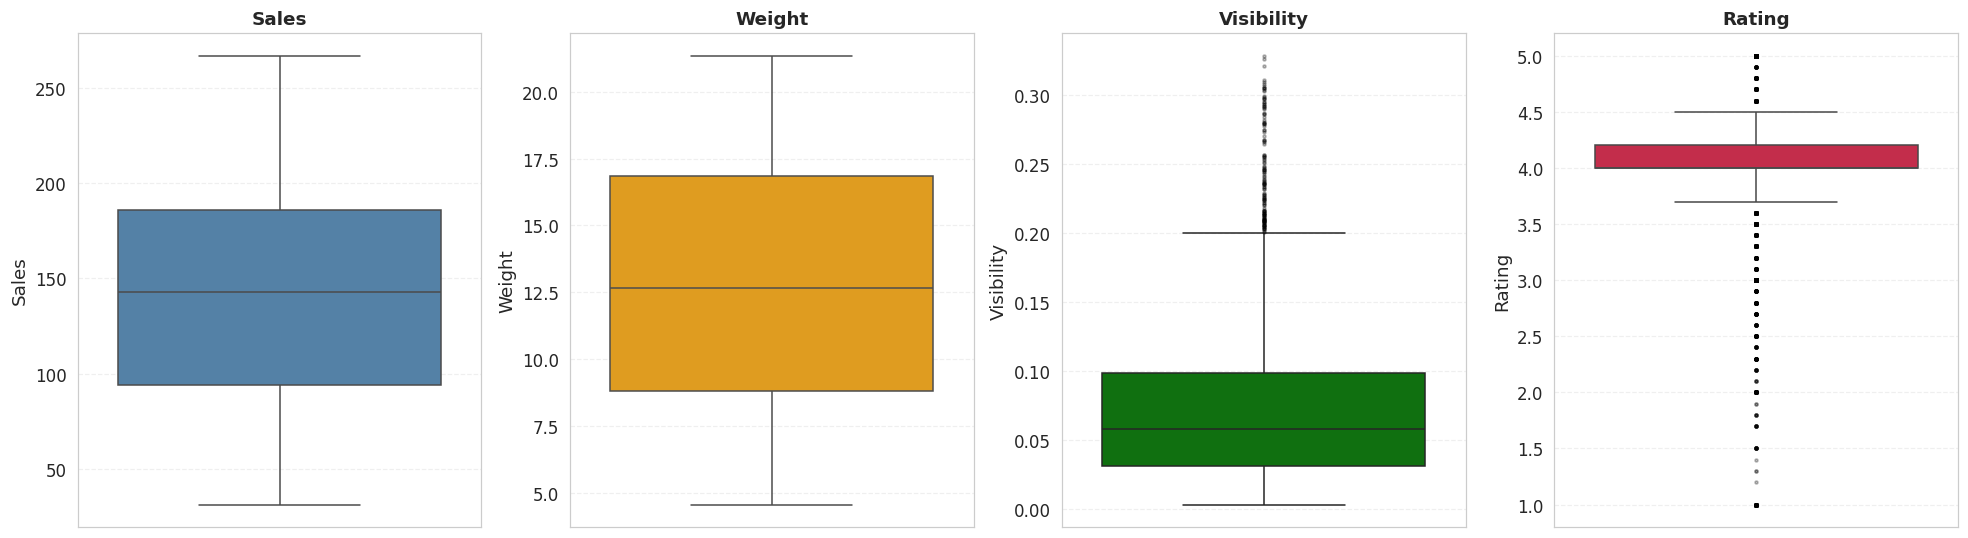

In [12]:
rows = []

for c in ['sales', 'weight', 'visibility', 'rating']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1

    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    rows.append([
        c,
        round(lo, 2),
        round(hi, 2),
        (df[c] < lo).sum(),
        (df[c] > hi).sum()
    ])

print(pd.DataFrame(
    rows,
    columns=['column', 'lower_fence', 'upper_fence', 'below', 'above']
).to_string(index=False))


# Create boxplots
fig, ax = plt.subplots(1, 4, figsize=(18, 5))

for a, c, col in zip(
    ax,
    ['sales', 'weight', 'visibility', 'rating'],
    ['steelblue', 'orange', 'green', 'crimson']
):
    sns.boxplot(
        y=df[c],
        ax=a,
        color=col,
        flierprops={
            'marker': 'o',
            'markersize': 2,
            'markerfacecolor': 'black',
            'markeredgecolor': 'black',
            'alpha': 0.25
        }
    )

    a.set_title(c.capitalize(), fontsize=12)
    a.set_ylabel(c.capitalize())
    a.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

**Observation:** `sales` and `weight` have **no outliers**. `visibility` has 144 high values (above 0.20, maximum 0.33), but these are plausible shelf shares, so they were kept. The 1,931 'outliers' flagged for `rating` are an artifact of the 4.0 spike: because 39% of ratings are exactly 4.0, the IQR is very narrow, so ordinary ratings of 3.5 or 4.6 get flagged. No values were removed.

# **Task 2.4: Same information shown in the same way**

In [13]:
print('Fat content labels BEFORE:', df['fat_content'].value_counts().to_dict())
df['fat_content'] = df['fat_content'].replace({'LF':'Low Fat','low fat':'Low Fat','reg':'Regular'})
# Non-consumables (NC) cannot have a fat content, so label them separately
df.loc[df['group']=='Non-Consumable', 'fat_content'] = 'Non-Edible'
print('Fat content labels AFTER :', df['fat_content'].value_counts().to_dict())
print()
# Outlet attributes should be fixed for an outlet
print('Distinct values per outlet (max):')
print(df.groupby('outlet_id')[['est_year','size','location','outlet_type']].nunique().max())
print()
print('Outlet size by outlet (records):')
print(pd.crosstab(df['outlet_id'], df['size']))

Fat content labels BEFORE: {'Low Fat': 5089, 'Regular': 2889, 'LF': 316, 'reg': 117, 'low fat': 112}
Fat content labels AFTER : {'Low Fat': 3918, 'Regular': 3006, 'Non-Edible': 1599}

Distinct values per outlet (max):
est_year       1
size           3
location       1
outlet_type    1
dtype: int64

Outlet size by outlet (records):
size       High  Medium  Small
outlet_id                     
OUT010      233     265     57
OUT013      932       0      0
OUT017      314     244    368
OUT018        0     928      0
OUT019        0       0    528
OUT027        0     935      0
OUT035        0       0    930
OUT045      274     329    326
OUT046        0       0    930
OUT049        0     930      0


Outlet **size is inconsistent** for OUT010, OUT017 and OUT045: the same outlet appears with two or three sizes. An outlet only has one real size, so we assign each outlet its **most frequent** size. This is an assumption and should be confirmed with the source system. Size-based conclusions below are lower confidence than the others.

In [14]:
df['size'] = df.groupby('outlet_id')['size'].transform(lambda s: s.mode().iloc[0])
print(df.groupby('outlet_id')['size'].first().to_frame().T.to_string())
print()
print(pd.crosstab(df.groupby('outlet_id')['outlet_type'].first(), df.groupby('outlet_id')['size'].first()))
df.to_csv('blinkit_clean.csv', index=False)
print('\nClean data saved. Shape:', df.shape)

outlet_id  OUT010 OUT013 OUT017  OUT018 OUT019  OUT027 OUT035  OUT045 OUT046  OUT049
size       Medium   High  Small  Medium  Small  Medium  Small  Medium  Small  Medium

size               High  Medium  Small
outlet_type                           
Grocery Store         0       1      1
Supermarket Type1     1       2      3
Supermarket Type2     0       1      0
Supermarket Type3     0       1      0

Clean data saved. Shape: (8523, 13)


**Observation:** Two consistency problems were fixed. (1) **Fat content** used five labels for two categories (`Low Fat`, `LF`, `low fat`, `Regular`, `reg`); these were merged, and all 1,599 non-consumable records (which cannot have a fat content) were relabelled `Non-Edible`. (2) **Outlet size** was inconsistent for OUT010, OUT017 and OUT045; each outlet was assigned its most frequent size. Note that even after this, a 'Grocery Store' ends up as Medium for OUT010, so size labels should be verified with the business.

# **Objective 3: Find Out What Is Driving Better Sales Performance**

## **Task 3.1: Which product types sell more?**

                       total_sales  avg_sales  records  share_pct
item_type                                                        
Fruits and Vegetables     178124.1      144.6     1232       14.8
Snack Foods               175433.9      146.2     1200       14.6
Household                 135976.5      149.4      910       11.3
Frozen Foods              118558.9      138.5      856        9.9
Dairy                     101276.5      148.5      682        8.4
Canned                     90706.7      139.8      649        7.5
Baking Goods               81894.7      126.4      648        6.8
Health and Hygiene         68025.8      130.8      520        5.7
Meat                       59449.9      139.9      425        4.9
Soft Drinks                58514.2      131.5      445        4.9
Breads                     35379.1      141.0      251        2.9
Hard Drinks                29334.7      137.1      214        2.4
Others                     22451.9      132.9      169        1.9
Starchy Fo

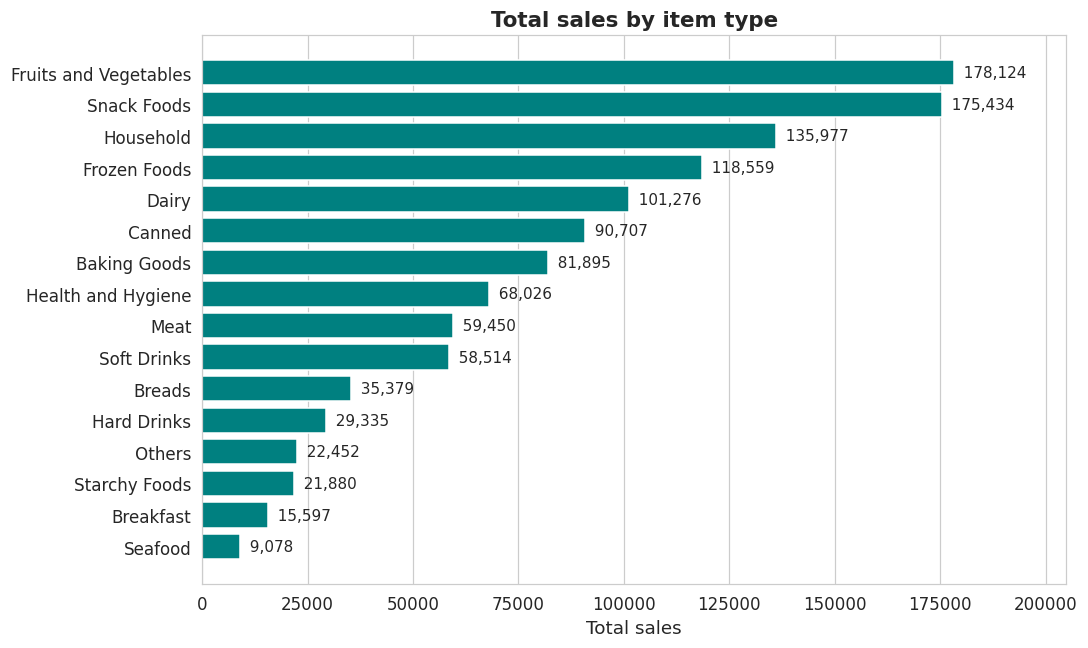

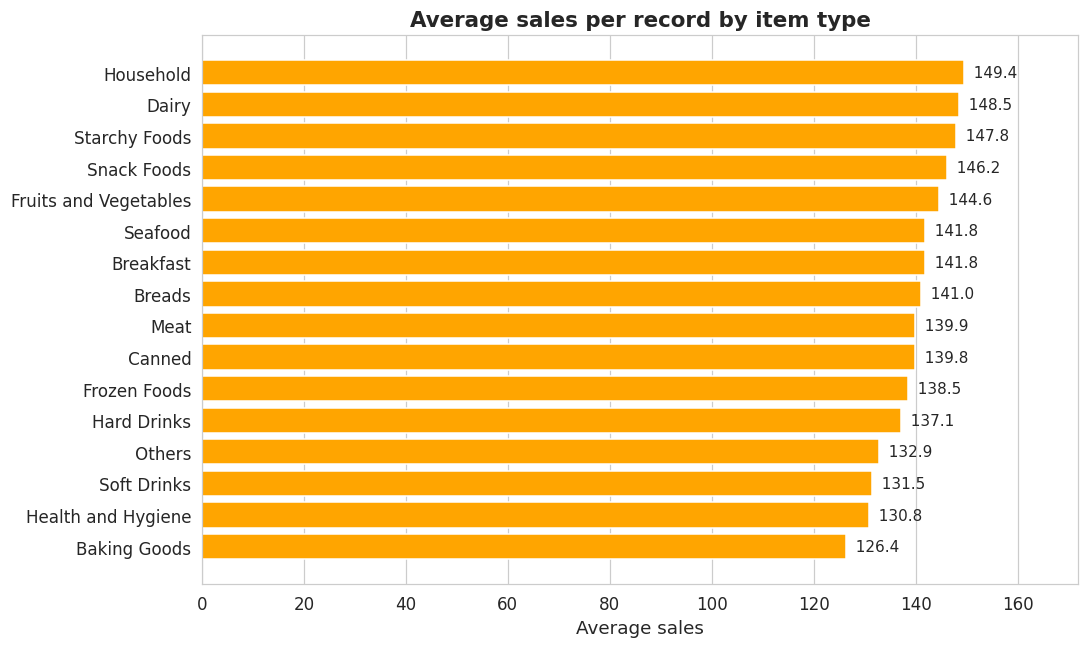

                     sum   mean
group                          
Drinks          104650.2  131.0
Food            870577.0  142.1
Non-Consumable  226454.3  141.6
                  sum   mean  count
fat_content                        
Low Fat      549865.4  140.3   3918
Non-Edible   226454.3  141.6   1599
Regular      425361.8  141.5   3006


In [15]:
it = df.groupby('item_type').agg(total_sales=('sales','sum'), avg_sales=('sales','mean'), records=('sales','size'))
it['share_pct'] = it['total_sales']/it['total_sales'].sum()*100
print(it.sort_values('total_sales', ascending=False).round(1))

hbar(it['total_sales'], 'Total sales by item type', 'Total sales', 'teal')
hbar(it['avg_sales'], 'Average sales per record by item type', 'Average sales', 'orange', '{:.1f}')
print(df.groupby('group')['sales'].agg(['sum','mean']).round(1))
print(df.groupby('fat_content')['sales'].agg(['sum','mean','count']).round(1))

**Observation:** Fruits & Vegetables (178K, 14.8%) and Snack Foods (175K, 14.6%) lead on total sales, followed by Household (136K) and Frozen Foods (119K). Much of this is simply range size: **per record, the best performers are Household (149), Dairy (149) and Starchy Foods (148)**, while Baking Goods (126), Health & Hygiene (131) and Soft Drinks (131) are lowest. By group, drinks average 131 per record versus about 142 for food and non-consumables. Fat content makes essentially no difference (140-142).

## **Task 3.2: Which outlets perform better?**

                   total_sales  avg_sales  records  outlets  sales_per_outlet  records_per_outlet
outlet_type                                                                                      
Grocery Store         151939.1      140.3     1083        2           75969.6               541.5
Supermarket Type1     787549.9      141.2     5577        6          131258.3               929.5
Supermarket Type2     131477.8      141.7      928        1          131477.8               928.0
Supermarket Type3     130714.7      139.8      935        1          130714.7               935.0


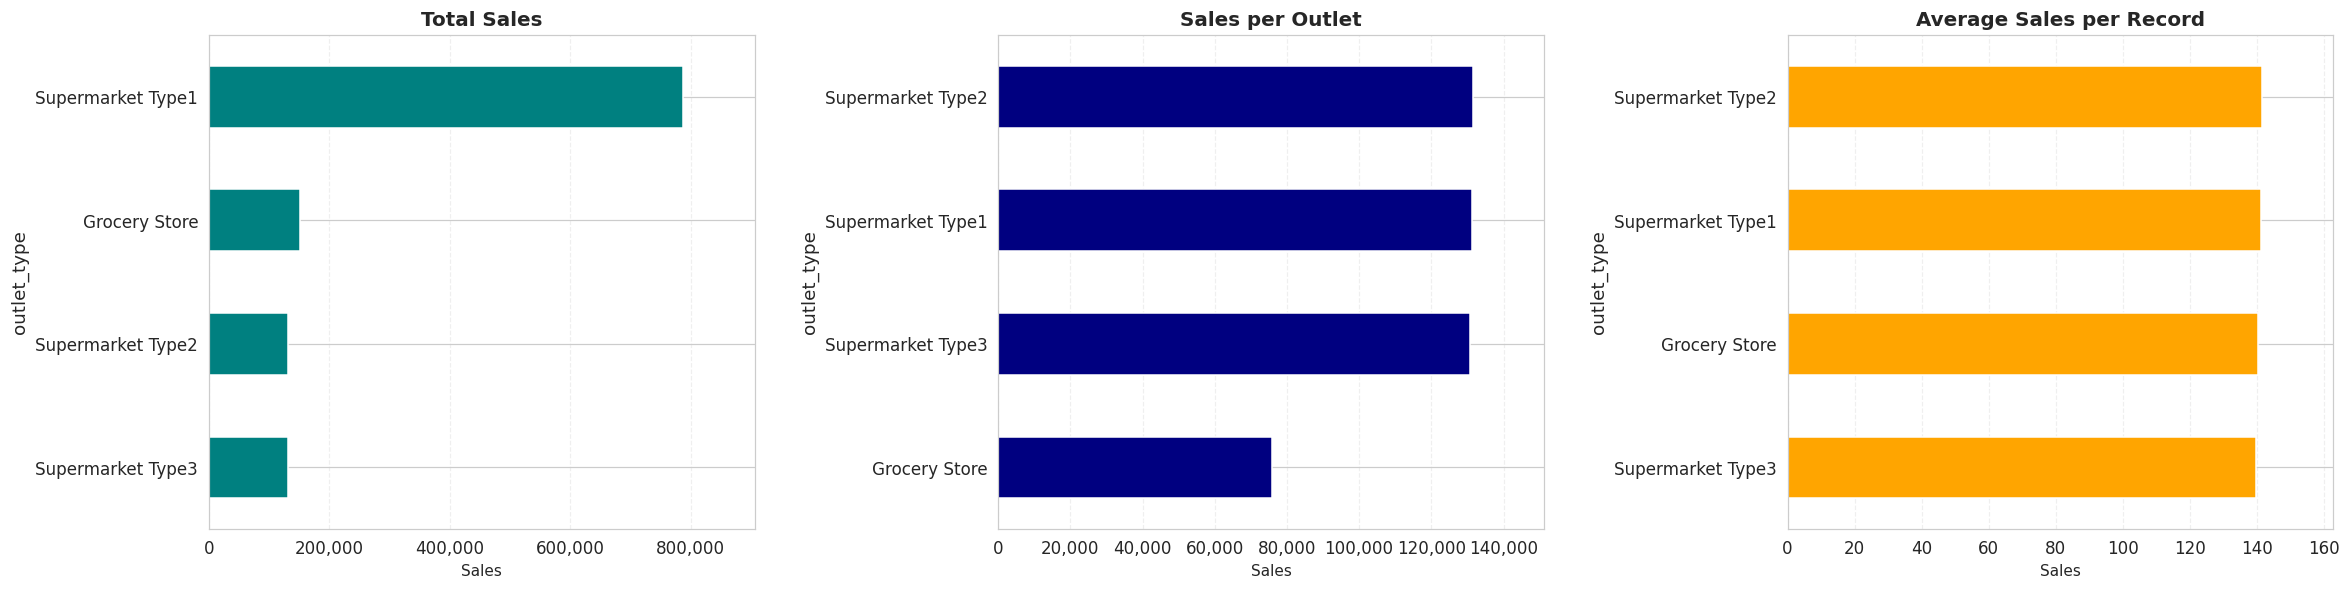


Analysis by Size:
        total_sales  avg_sales  outlets  sales_per_outlet
size                                                     
High       131809.0      141.4        1          131809.0
Medium     601743.7      140.7        5          120348.7
Small      468128.8      141.3        4          117032.2

Analysis by Location:
          total_sales  avg_sales  outlets  sales_per_outlet
location                                                   
Tier 1       336397.8      140.9        3          112132.6
Tier 2       393150.6      141.2        3          131050.2
Tier 3       472133.0      140.9        4          118033.3


In [16]:
ot = df.groupby('outlet_type').agg(
    total_sales=('sales', 'sum'),
    avg_sales=('sales', 'mean'),
    records=('sales', 'size'),
    outlets=('outlet_id', 'nunique')
)

ot['sales_per_outlet'] = ot['total_sales'] / ot['outlets']
ot['records_per_outlet'] = ot['records'] / ot['outlets']

print(ot.round(1).to_string())


# Create three charts
fig, ax = plt.subplots(1, 3, figsize=(22, 6))

for a, c, t, col in zip(
    ax,
    ['total_sales', 'sales_per_outlet', 'avg_sales'],
    ['Total Sales', 'Sales per Outlet', 'Average Sales per Record'],
    ['teal', 'navy', 'orange']
):
    ot[c].sort_values().plot.barh(ax=a, color=col)

    a.set_title(t, fontsize=13, fontweight='bold')
    a.set_xlabel('Sales', fontsize=10)
    a.ticklabel_format(axis='x', style='plain')
    a.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'{x:,.0f}')
    )
    a.grid(axis='x', linestyle='--', alpha=0.3)
    a.set_axisbelow(True)

    # Add space after the longest bar
    a.margins(x=0.15)

plt.tight_layout(pad=3)
plt.show()


# Outlet size and location analysis
for col in ['size', 'location']:

    g = df.groupby(col).agg(
        total_sales=('sales', 'sum'),
        avg_sales=('sales', 'mean'),
        outlets=('outlet_id', 'nunique')
    )

    g['sales_per_outlet'] = g['total_sales'] / g['outlets']

    print(f'\nAnalysis by {col.capitalize()}:')
    print(g.round(1).to_string())

**Observation:** Supermarkets lead on totals only because they stock more: a supermarket averages about **131K per outlet versus 76K for a grocery store**, but sales per record are almost identical across all outlet types (139.8-141.7), sizes (140.7-141.4) and location tiers (140.9-141.2). Tier 3 has the highest total only because it has four outlets. Size results have lower confidence because of the size inconsistency found earlier.

# **Task 3.3: Are visibility, weight, ratings and outlet characteristics linked to sales?**

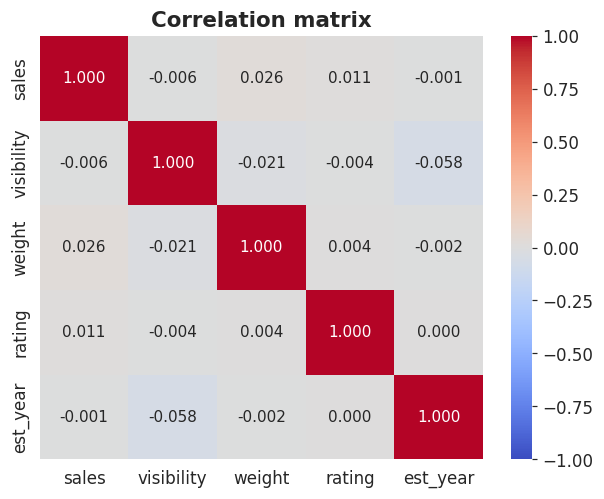

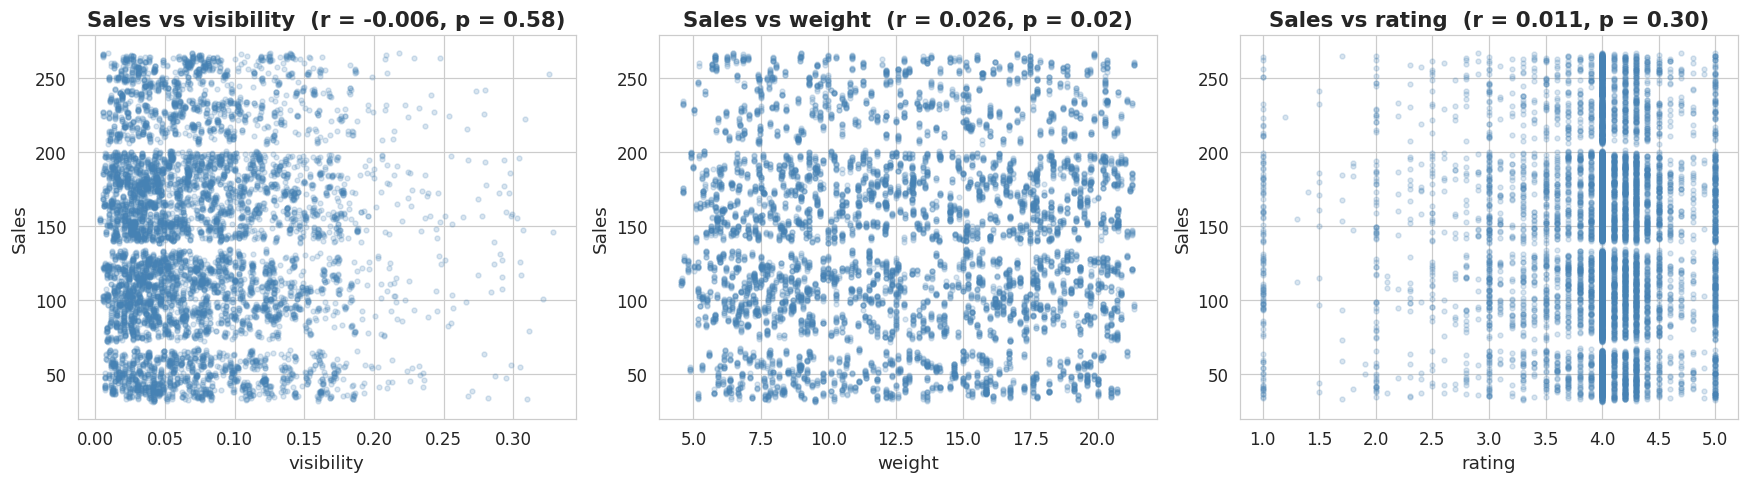

     factor     F  p_value significant_at_5%
  item_type  7.16    0.000               Yes
      group 11.47    0.000               Yes
fat_content  0.40    0.673                No
outlet_type  0.22    0.882                No
       size  0.10    0.903                No
   location  0.02    0.983                No
  outlet_id  0.31    0.973                No
   est_year  0.35    0.948                No


In [17]:
num = df[['sales','visibility','weight','rating','est_year']]
plt.figure(figsize=(6.5, 5))
sns.heatmap(num.corr(), annot=True, fmt='.3f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix'); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(ax, ['visibility','weight','rating']):
    a.scatter(df[c], df['sales'], alpha=.2, s=10, color='steelblue')
    r, p = stats.pearsonr(df[c], df['sales'])
    a.set_title(f'Sales vs {c}  (r = {r:.3f}, p = {p:.2f})'); a.set_xlabel(c); a.set_ylabel('Sales')
plt.tight_layout(); plt.show()

# Do category averages differ more than chance? (one-way ANOVA)
res = []
for c in ['item_type','group','fat_content','outlet_type','size','location','outlet_id','est_year']:
    f, p = stats.f_oneway(*[g['sales'].values for _, g in df.groupby(c)])
    res.append([c, round(f,2), round(p,3), 'Yes' if p < 0.05 else 'No'])
print(pd.DataFrame(res, columns=['factor','F','p_value','significant_at_5%']).to_string(index=False))

**Observation:** Visibility (r = -0.006), weight (r = 0.026) and rating (r = 0.011) have **essentially no relationship with sales**. Weight is nominally significant (p = 0.017) but explains under 0.1% of the variation, so it has no practical value. The ANOVA tests show that only **item type and product group** differ significantly in average sales; fat content, outlet type, size, location, individual outlet and establishment year do not (all p > 0.67). Higher shelf visibility or better ratings are therefore not, by themselves, associated with higher sales in this data.

# **Task 3.4: Better vs lower-performing products and outlets**

In [22]:
od = df.groupby('outlet_id').agg(
    total_sales=('sales', 'sum'),
    avg_sales=('sales', 'mean'),
    records=('sales', 'size'),
    outlet_type=('outlet_type', 'first')
)

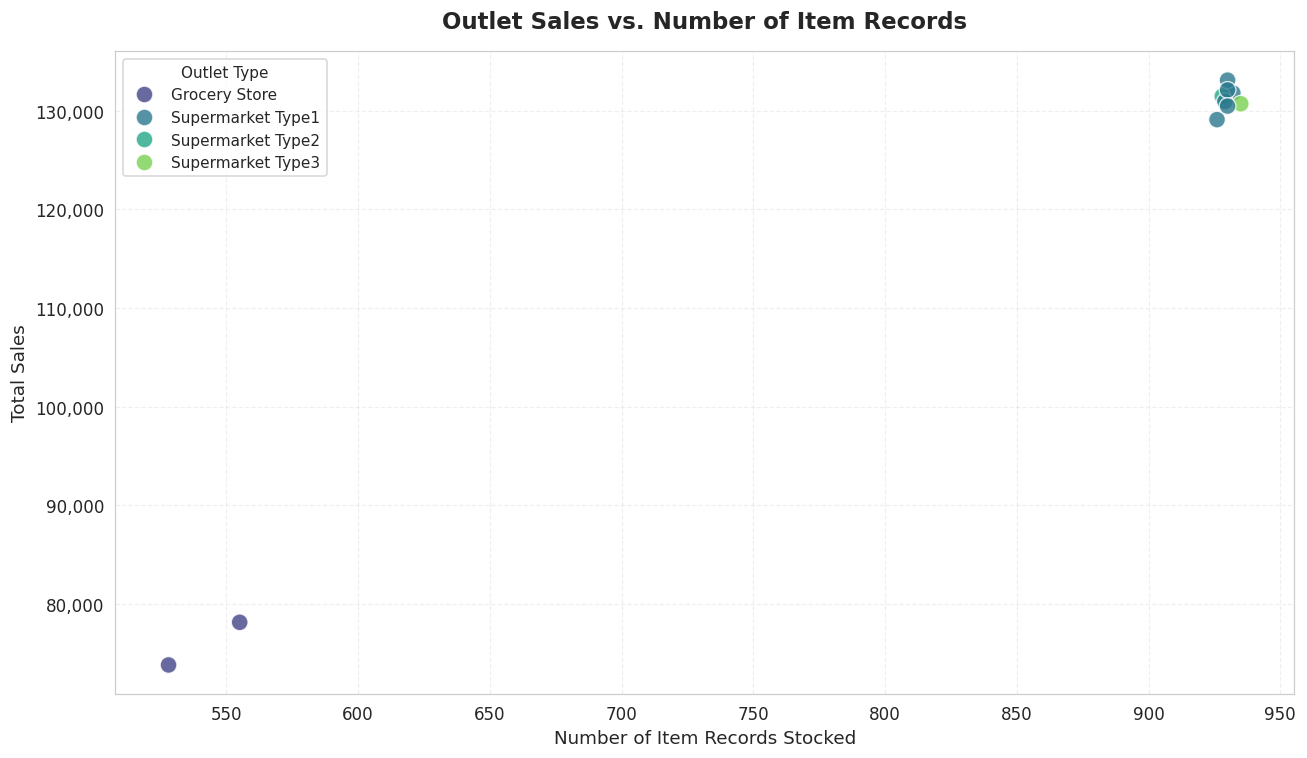

In [23]:
# Clean outlet sales scatter plot
fig, ax = plt.subplots(figsize=(12, 7))

sns.scatterplot(
    data=od,
    x='records',
    y='total_sales',
    hue='outlet_type',
    s=120,
    alpha=0.8,
    palette='viridis',
    ax=ax
)

ax.set_title(
    'Outlet Sales vs. Number of Item Records',
    fontsize=15,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Number of Item Records Stocked', fontsize=12)
ax.set_ylabel('Total Sales', fontsize=12)

# Format sales values with commas
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:,.0f}')
)

ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(title='Outlet Type', loc='best')

plt.tight_layout()
plt.show()

**Observation:** The top and bottom 25% of records look the same on visibility (0.071), weight (about 13) and rating (3.97) and have a similar fat mix, so the data offers no product attribute that separates strong from weak sales. The clearest difference is structural: **an outlet's total sales are almost perfectly explained by how many items it stocks** (correlation 0.999), while average sales per record explain far less (0.34). Between item types, the gap is about 23 per record (Household 149 vs Baking Goods 126).

# **Objective 4: Help Management Make Better Business Decisions**

# **Task 4.1: Products contributing most to sales**

                          sales  share_pct  cum_share_pct
item_type                                                
Fruits and Vegetables  178124.0       14.8           14.8
Snack Foods            175434.0       14.6           29.4
Household              135977.0       11.3           40.7
Frozen Foods           118559.0        9.9           50.6
Dairy                  101276.0        8.4           59.0
Canned                  90707.0        7.5           66.6
Baking Goods            81895.0        6.8           73.4
Health and Hygiene      68026.0        5.7           79.1
Meat                    59450.0        4.9           84.0
Soft Drinks             58514.0        4.9           88.9
Breads                  35379.0        2.9           91.8
Hard Drinks             29335.0        2.4           94.3
Others                  22452.0        1.9           96.1
Starchy Foods           21880.0        1.8           97.9
Breakfast               15597.0        1.3           99.2
Seafood       

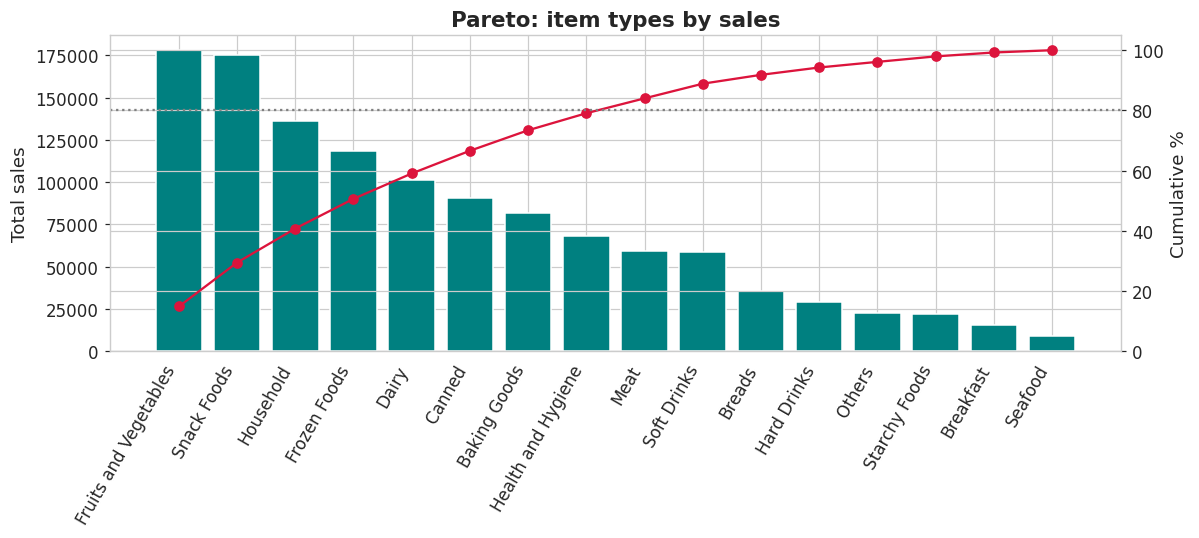


Top 10 individual items:
                     item_type  total_sales  outlets
item_id                                             
FDU12             Baking Goods       2371.0        9
FDT07    Fruits and Vegetables       2307.0        9
NCQ06                Household       2295.0        9
FDL58              Snack Foods       2112.0        8
NCB31                Household       2105.0        8
FDX31    Fruits and Vegetables       2104.0        9
FDF05             Frozen Foods       2103.0        8
FDR59                   Breads       2097.0        8
FDP28             Frozen Foods       2088.0        8
FDA04             Frozen Foods       2072.0        8


In [24]:
par = it['total_sales'].sort_values(ascending=False)
cum = par.cumsum()/par.sum()*100
print(pd.DataFrame({'sales': par.round(0), 'share_pct': (par/par.sum()*100).round(1), 'cum_share_pct': cum.round(1)}))

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(par.index, par.values, color='teal'); ax.set_ylabel('Total sales')
ax2 = ax.twinx(); ax2.plot(par.index, cum.values, color='crimson', marker='o'); ax2.set_ylabel('Cumulative %'); ax2.set_ylim(0, 105)
ax2.axhline(80, color='grey', ls=':'); ax.set_title('Pareto: item types by sales'); plt.setp(ax.get_xticklabels(), rotation=60, ha='right'); plt.tight_layout(); plt.show()

top_items = df.groupby('item_id').agg(item_type=('item_type','first'), total_sales=('sales','sum'), outlets=('outlet_id','nunique')).nlargest(10, 'total_sales').round(0)
print('\nTop 10 individual items:'); print(top_items)

**Observation:** Eight item types (Fruits & Vegetables, Snack Foods, Household, Frozen Foods, Dairy, Canned, Baking Goods, Health & Hygiene) generate **79% of sales**, and the top five generate 59%. The bottom five (Others, Starchy Foods, Breakfast, Seafood, Hard Drinks) together bring in under 10%. Top individual items each total roughly 2,000-2,400 in sales, but the lead is thin, so no single product dominates.

# **Task 4.2: Outlets and locations performing better**

                 outlet_type location    size  total_sales  avg_sales  \
outlet_id                                                               
OUT035     Supermarket Type1   Tier 2   Small     133103.9      143.1   
OUT046     Supermarket Type1   Tier 1   Small     132113.4      142.1   
OUT013     Supermarket Type1   Tier 3    High     131809.0      141.4   
OUT018     Supermarket Type2   Tier 3  Medium     131477.8      141.7   
OUT045     Supermarket Type1   Tier 2  Medium     130942.8      141.0   
OUT027     Supermarket Type3   Tier 3  Medium     130714.7      139.8   
OUT049     Supermarket Type1   Tier 1  Medium     130476.9      140.3   
OUT017     Supermarket Type1   Tier 2   Small     129104.0      139.4   
OUT010         Grocery Store   Tier 3  Medium      78131.6      140.8   
OUT019         Grocery Store   Tier 1   Small      73807.6      139.8   

           records  avg_rating  share_pct  
outlet_id                                  
OUT035         930         3.9     

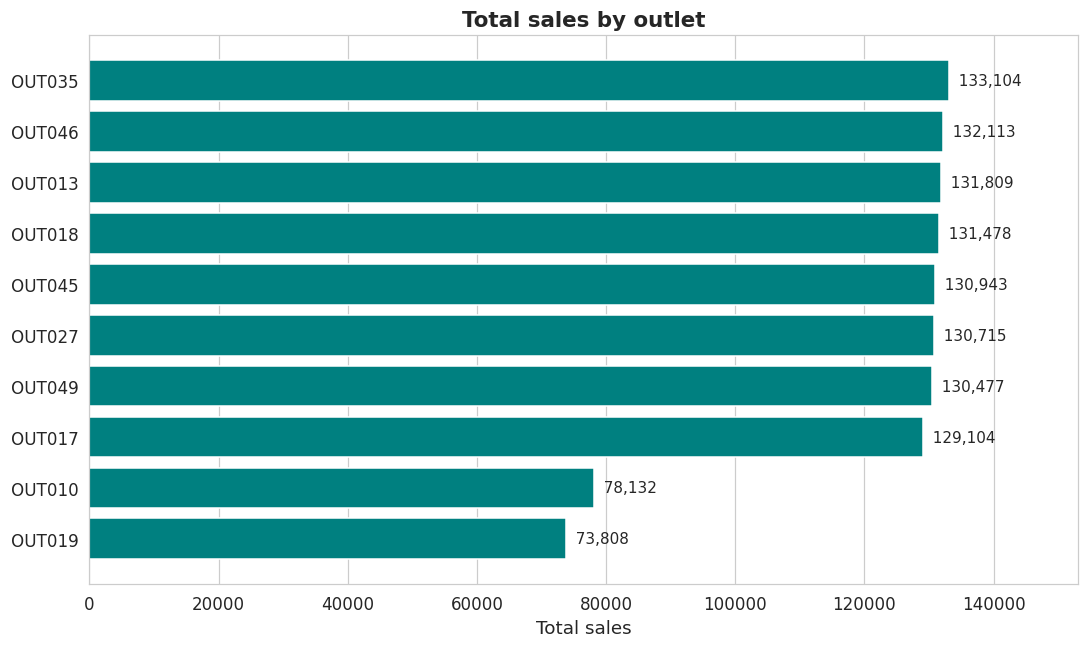


           total_sales  outlets  avg_sales  sales_per_outlet
location                                                   
Tier 1       336397.8        3      140.9          112132.6
Tier 2       393150.6        3      141.2          131050.2
Tier 3       472133.0        4      140.9          118033.3


In [25]:
rank = df.groupby('outlet_id').agg(outlet_type=('outlet_type','first'), location=('location','first'), size=('size','first'),
                                  total_sales=('sales','sum'), avg_sales=('sales','mean'), records=('sales','size'),
                                  avg_rating=('rating','mean')).sort_values('total_sales', ascending=False).round(1)
rank['share_pct'] = (rank['total_sales']/rank['total_sales'].sum()*100).round(1)
print(rank)
hbar(rank['total_sales'], 'Total sales by outlet', 'Total sales', 'teal')

loc = df.groupby('location').agg(total_sales=('sales','sum'), outlets=('outlet_id','nunique'), avg_sales=('sales','mean'))
loc['sales_per_outlet'] = loc['total_sales']/loc['outlets']
print('\n', loc.round(1))

**Observation:** Eight outlets are tightly grouped at 129K-133K; **OUT035 (Supermarket Type1, Tier 2) is first** at 133K, followed by OUT046 and OUT013. The two grocery stores, OUT010 and OUT019, are far behind at 78K and 74K. By tier, Tier 2 earns the most per outlet (131K), compared with 118K for Tier 3 and 112K for Tier 1, although with only three or four outlets per tier this should be read cautiously.

# **Task 4.3: Where can performance be improved?**

In [26]:
overall_avg = df['sales'].mean()
weak_items = it[it['avg_sales'] < overall_avg].sort_values('avg_sales')[['avg_sales','records','total_sales']].round(1)
print(f'Item types below overall average ({overall_avg:.1f}) per record:'); print(weak_items)

small_cats = it[it['share_pct'] < 2].sort_values('share_pct')[['records','total_sales','share_pct']].round(1)
print('\nCategories with under 2% of sales (narrow range):'); print(small_cats)

low_out = rank[rank['avg_sales'] < overall_avg][['outlet_type','location','avg_sales','records']]
print('\nOutlets below overall average per record:'); print(low_out)

# Low-selling items: how many records fall under 75 (clearly weak) and where
weak = df[df['sales'] < 75]
print(f'\nRecords with sales under 75: {len(weak)} ({len(weak)/len(df)*100:.1f}% of records)')
print(weak['item_type'].value_counts().head(5))

# Gap between grocery stores and supermarkets
gs = rank[rank['outlet_type']=='Grocery Store']; sm = rank[rank['outlet_type']!='Grocery Store']
print(f"\nAvg sales per outlet: grocery stores {gs['total_sales'].mean():,.0f} vs supermarkets {sm['total_sales'].mean():,.0f}")
print(f"Avg records per outlet: grocery stores {gs['records'].mean():.0f} vs supermarkets {sm['records'].mean():.0f}")

Item types below overall average (141.0) per record:
                    avg_sales  records  total_sales
item_type                                          
Baking Goods            126.4      648      81894.7
Health and Hygiene      130.8      520      68025.8
Soft Drinks             131.5      445      58514.2
Others                  132.9      169      22451.9
Hard Drinks             137.1      214      29334.7
Frozen Foods            138.5      856     118558.9
Canned                  139.8      649      90706.7
Meat                    139.9      425      59449.9
Breads                  141.0      251      35379.1

Categories with under 2% of sales (narrow range):
               records  total_sales  share_pct
item_type                                     
Seafood             64       9077.9        0.8
Breakfast          110      15596.7        1.3
Starchy Foods      148      21880.0        1.8
Others             169      22451.9        1.9

Outlets below overall average per record:

**Observation:** Improvement areas: (a) **Grocery stores** sell about 42% less per outlet, entirely because they list about 540 records versus about 930; their per-record sales are normal. (b) **Baking Goods, Health & Hygiene and Soft Drinks** are the weakest item types per record (126-132 vs 141 average), and Baking Goods is a large category (648 records, 6.8% of sales). (c) **Seafood, Breakfast, Starchy Foods and 'Others'** each contribute under 2% of sales. (d) **OUT017, OUT019 and OUT027** have the lowest sales per record (139.4-139.8), though the gap to the best outlet (143.1) is small. (e) 16% of records sell under 75 per record, spread across the large categories.

# **Task 4.4: Practical suggestions**

1. **Widen the range in grocery stores (OUT010, OUT019).** Because sales per record are the same everywhere, adding items is the most direct lever: bringing each grocery store from about 540 towards about 930 records would, at 141 per record, add roughly 55K per outlet. Start with the best per-record categories (Household, Dairy, Starchy Foods) and test the effect before full rollout.
2. **Protect the core.** Fruits & Vegetables, Snack Foods, Household, Frozen Foods and Dairy produce 59% of sales; prioritise their availability and stock planning across all outlets.
3. **Review the weak categories.** Baking Goods, Health & Hygiene and Soft Drinks sell 7-10% less per record than average. Check pricing, pack sizes and range overlap, and drop the weakest items rather than adding more.
4. **Test, don't assume, on visibility and ratings.** The data shows no link between shelf visibility, ratings or weight and sales, so avoid large investments in re-merchandising based on this evidence; run controlled in-store tests instead.
5. **Fix the data.** Collect weight for OUT019 and OUT027, correct the outlet-size records, investigate the 39% of ratings that equal exactly 4.0, and add date, quantity and price fields so future analysis can cover trends, demand and margins.
6. **Selective expansion of niche categories.** Seafood, Breakfast and Starchy Foods sell normally per record (142-148) but have few listings; a modest range extension could add sales at low risk.

# **Summary of Key Findings**

- BlinkIT sells **1.2M** across 10 outlets and 16 item types; customers rate products **3.97** on average (though 39% of ratings are exactly 4.0, which looks like a default).
- **Data quality:** 17% of weights were missing, 6% of visibility values were zero, fat-content labels were inconsistent, and outlet size was recorded inconsistently for three outlets. All were fixed or flagged; there were no duplicates or sales outliers.
- **What drives sales:** outlet total sales follow **how many items an outlet stocks**, not how well each item sells. Average sales per record are nearly identical across outlet type, size, location and year.
- **Product view:** Fruits & Vegetables, Snack Foods and Household lead on totals; Household, Dairy and Starchy Foods lead per record; Baking Goods, Health & Hygiene and Soft Drinks lag.
- **Biggest opportunity:** the two grocery stores stock about 40% fewer items and sell 42% less per outlet.
- **Limits:** the data has no dates, quantities or prices, so it cannot show trends, demand or profitability, and the findings describe association, not cause.